# 02 — Preparación: segmentación, tamaño y separación de `mixed_quality`

**Fase CRISP-DM:** preparación de los datos.

La lógica está en `src/data/segmentacion.py`, `src/data/tamano.py` y `src/data/preprocesamiento.py`; aquí se muestra paso a paso y se revisa sobre el dataset. La justificación matemática está en `docs/formulacion_matematica.md`.

In [1]:
import sys, json
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

from src.config import DATA_RAW_KAGGLE, DATA_PROCESSED, DATA_INTERIM, RESULTADOS, SEMILLA
from src.data import segmentacion as seg
from src.data.tamano import estimar_tamano
from src.data.preprocesamiento import tamanos_dataset, umbrales_por_fruta, recortes_mixed
from src.utils.visualizacion import estilo, guardar_figura, leer_rgb

estilo()
inv = pd.read_csv(DATA_PROCESSED / "inventario_kaggle.csv")
indiv = inv[inv["calidad"].isin(["good", "bad"])]
frutas = sorted(indiv["fruta"].unique())

## 1. Segmentación paso a paso

1. Se estima el color del fondo como la mediana de una franja del borde, en CIELab.
2. Se calcula la distancia de color $\Delta E$ de cada píxel al fondo.
3. Se umbraliza con Otsu, que elige el $t^*$ que maximiza la varianza entre clases $\sigma_B^2(t)=\omega_0\omega_1(\mu_0-\mu_1)^2$.
4. Apertura y cierre morfológicos, relleno de huecos y componente conexo mayor.
5. Como muchas fotos del dataset tienen fondos con textura, la máscara de Otsu (intersectada con Otsu sobre la saturación) se usa como semilla de **GrabCut**, que la refina con un modelo de color de mezclas de gaussianas y un corte de grafo [Rother et al., 2004].

Umbral de OpenCV: 97  |  umbral calculado a mano: 97


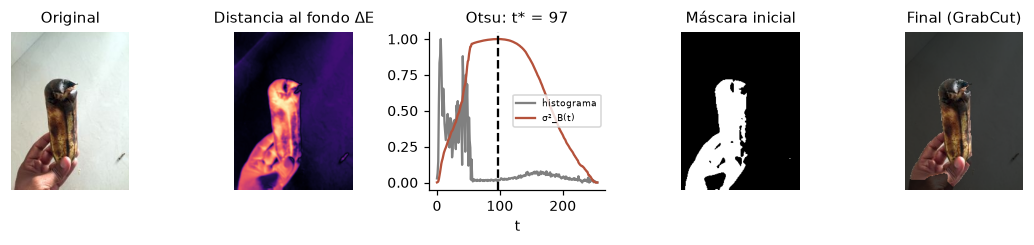

In [2]:
fila = indiv[(indiv["fruta"] == frutas[0]) & (indiv["calidad"] == "bad")].sample(1, random_state=SEMILLA).iloc[0]
rgb = leer_rgb(DATA_RAW_KAGGLE / fila["ruta"])
bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)

dist = seg.mapa_distancia_fondo(bgr)
t_otsu, m0 = cv2.threshold(dist, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
m_final = seg.mascara_fruta(bgr)

# Varianza entre clases calculada a mano para comprobar el umbral de OpenCV
hist = np.bincount(dist.ravel(), minlength=256).astype(float)
p = hist / hist.sum()
omega0 = np.cumsum(p)
mu = np.cumsum(p * np.arange(256))
mu_t = mu[-1]
with np.errstate(divide="ignore", invalid="ignore"):
    sigma_b = (mu_t * omega0 - mu) ** 2 / (omega0 * (1 - omega0))
t_manual = int(np.nanargmax(sigma_b))
print(f"Umbral de OpenCV: {t_otsu:.0f}  |  umbral calculado a mano: {t_manual}")

fig, axes = plt.subplots(1, 5, figsize=(10, 2.3))
axes[0].imshow(rgb); axes[0].set_title("Original")
axes[1].imshow(dist, cmap="magma"); axes[1].set_title("Distancia al fondo ΔE")
axes[2].plot(hist / hist.max(), color="gray", label="histograma")
axes[2].plot(np.nan_to_num(sigma_b) / np.nanmax(sigma_b), color="#b5523b", label="σ²_B(t)")
axes[2].axvline(t_manual, ls="--", color="k"); axes[2].set_title(f"Otsu: t* = {t_manual}")
axes[2].legend(fontsize=6); axes[2].set_xlabel("t")
axes[3].imshow(m0, cmap="gray"); axes[3].set_title("Máscara inicial")
superp = rgb.copy(); superp[m_final == 0] = (superp[m_final == 0] * 0.25).astype(np.uint8)
axes[4].imshow(superp); axes[4].set_title("Final (GrabCut)")
for a in axes[[0, 1, 3, 4]]:
    a.axis("off")
fig.tight_layout()
guardar_figura(fig, "seg_pasos", raster=True)
plt.show()

### Otsu frente a GrabCut

Misma muestra aleatoria (2 imágenes por fruta y calidad) segmentada con los dos métodos. Amarillo: Otsu sobre $\Delta E$. Cian: GrabCut.

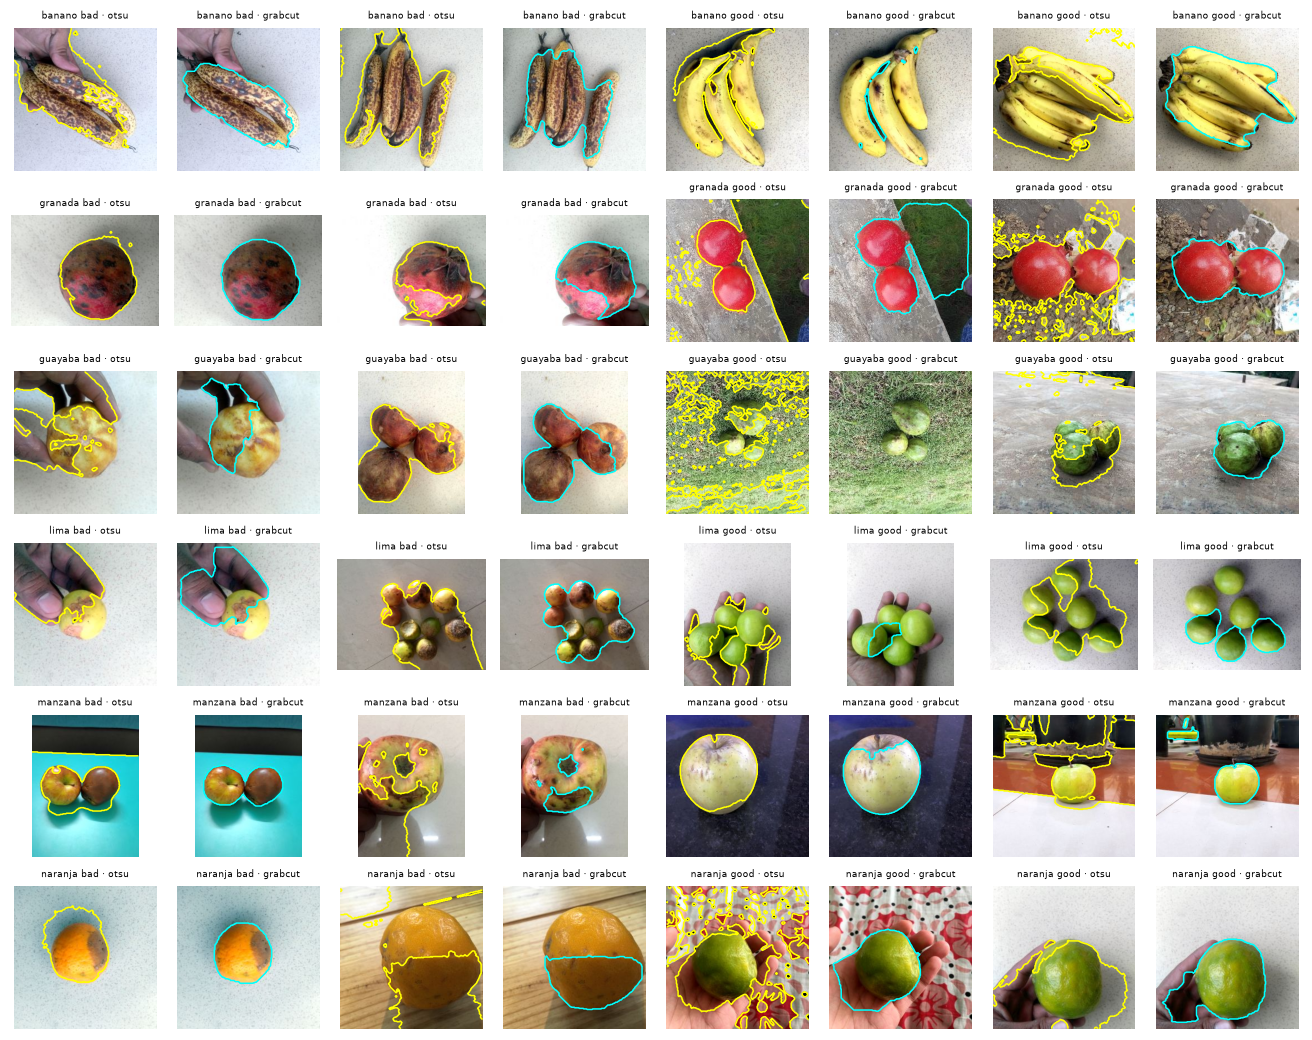

In [3]:
comp = indiv.groupby(["fruta", "calidad"]).sample(2, random_state=7)
fig, axes = plt.subplots(6, 8, figsize=(12, 9.5))
for k, (_, f) in enumerate(comp.iterrows()):
    rgb = leer_rgb(DATA_RAW_KAGGLE / f["ruta"])
    bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
    for j, (metodo, color) in enumerate([("otsu", "yellow"), ("grabcut", "cyan")]):
        ax = axes.ravel()[2 * k + j]
        ax.imshow(rgb)
        ax.contour(seg.mascara_binaria(bgr, metodo) > 0, colors=color, linewidths=1)
        ax.set_title(f"{f['fruta']} {f['calidad']} · {metodo}", fontsize=6)
        ax.axis("off")
fig.tight_layout()
guardar_figura(fig, "seg_otsu_vs_grabcut", raster=True)
plt.show()

## 2. Revisión sobre una muestra aleatoria (GrabCut)

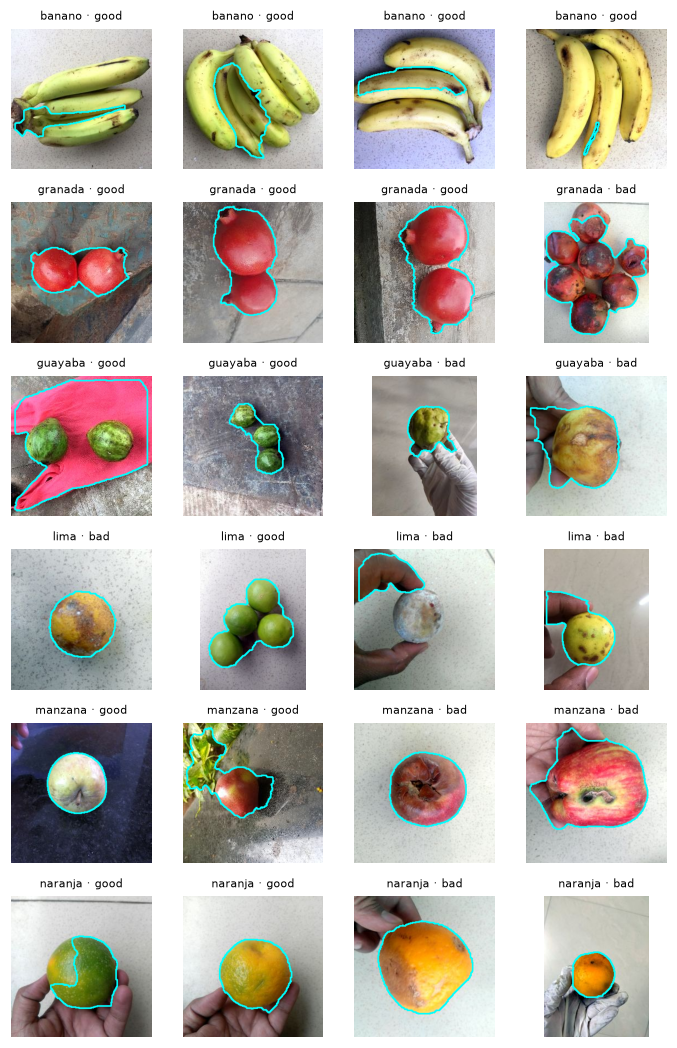

In [4]:
muestra = indiv.groupby("fruta").sample(4, random_state=SEMILLA)
fig, axes = plt.subplots(len(frutas), 4, figsize=(6.4, 1.6 * len(frutas)))
for ax, (_, f) in zip(axes.ravel(), muestra.iterrows()):
    rgb = leer_rgb(DATA_RAW_KAGGLE / f["ruta"])
    m = seg.mascara_fruta(cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR))
    contornos, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    vis = rgb.copy()
    cv2.drawContours(vis, contornos, -1, (0, 255, 255), 2)
    ax.imshow(vis); ax.set_title(f"{f['fruta']} · {f['calidad']}", fontsize=7); ax.axis("off")
fig.tight_layout()
guardar_figura(fig, "seg_muestra", raster=True)
plt.show()

## 3. Tamaño de todas las imágenes individuales

Para cada imagen: área $A$ de la máscara, diámetro equivalente $d = 2\sqrt{A/\pi}$ y $\hat d = d / \max(H, W)$. Se marcan como dudosas las máscaras que tocan el borde o que ocupan menos del 5 % o más del 95 % de la imagen.

In [5]:
ruta_tam = DATA_PROCESSED / "tamanos_kaggle.csv"
if ruta_tam.exists():
    tam = pd.read_csv(ruta_tam)
else:
    tam = tamanos_dataset(inv)
    tam.to_csv(ruta_tam, index=False)

tam["dudosa"] = tam["toca_borde"] | ~tam["area_rel"].between(0.05, 0.95)
print("Máscaras dudosas por fruta (%):")
print((100 * tam.groupby("fruta")["dudosa"].mean()).round(1))

Máscaras dudosas por fruta (%):
fruta
banano     14.6
granada    10.4
guayaba    12.0
lima       10.2
manzana     7.6
naranja     1.0
Name: dudosa, dtype: float64


In [6]:
umbrales = umbrales_por_fruta(tam)
(RESULTADOS / "umbrales_tamano.json").write_text(json.dumps(umbrales, indent=2), encoding="utf8")
pd.DataFrame(umbrales).T.round(3)

,p33,p66
banano,0.418,0.531
granada,0.499,0.584
guayaba,0.430,0.534
lima,0.366,0.467
manzana,0.431,0.557
naranja,0.456,0.548


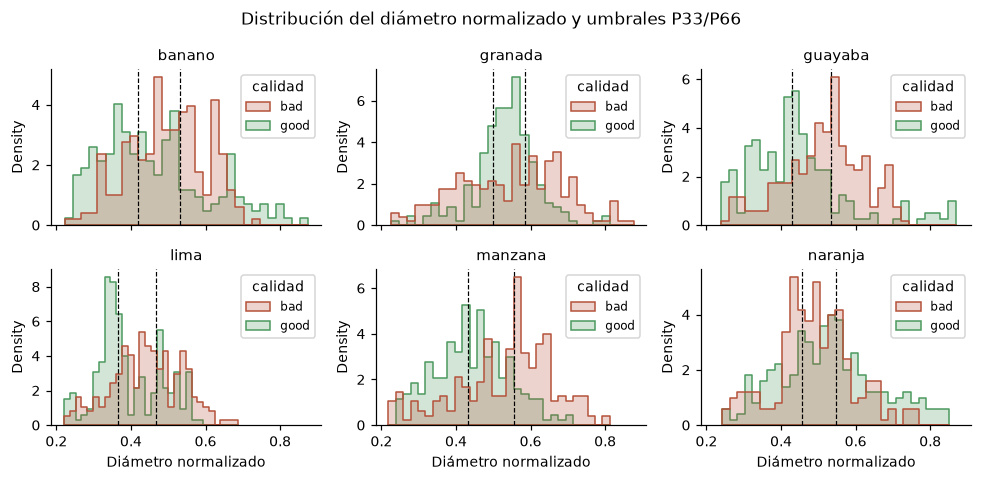

In [7]:
validas = tam[~tam["dudosa"]]
fig, axes = plt.subplots(2, 3, figsize=(9, 4.4), sharex=True)
for ax, f in zip(axes.ravel(), frutas):
    sub = validas[validas["fruta"] == f]
    sns.histplot(data=sub, x="diametro_norm", hue="calidad", bins=30, ax=ax, element="step",
                 palette={"good": "#4c9a5f", "bad": "#b5523b"}, stat="density", common_norm=False)
    for q in umbrales[f].values():
        ax.axvline(q, ls="--", color="k", lw=0.8)
    ax.set_title(f); ax.set_xlabel("Diámetro normalizado")
fig.suptitle("Distribución del diámetro normalizado y umbrales P33/P66")
fig.tight_layout()
guardar_figura(fig, "tamano_distribucion")
plt.show()

## 4. Separación de frutas en `mixed_quality`

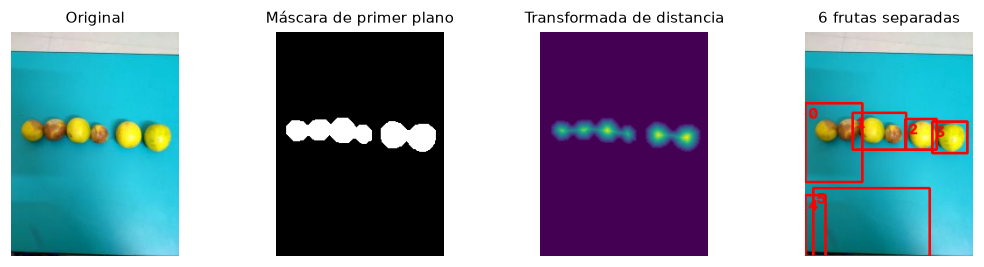

In [8]:
mixed = inv[inv["calidad"] == "mixed"]
fila = mixed.sample(1, random_state=SEMILLA + 3).iloc[0]
rgb = leer_rgb(DATA_RAW_KAGGLE / fila["ruta"])
bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
m = seg.mascara_binaria(bgr)
dist_t = cv2.distanceTransform(m, cv2.DIST_L2, 5)
frs = seg.separar_frutas(bgr)

vis = rgb.copy()
for k, fr in enumerate(frs):
    x, y, w, h = fr.caja
    cv2.rectangle(vis, (x, y), (x + w, y + h), (255, 0, 0), 2)
    cv2.putText(vis, str(k), (x + 4, y + 18), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)

fig, axes = plt.subplots(1, 4, figsize=(10, 2.5))
axes[0].imshow(rgb); axes[0].set_title("Original")
axes[1].imshow(m, cmap="gray"); axes[1].set_title("Máscara de primer plano")
axes[2].imshow(dist_t, cmap="viridis"); axes[2].set_title("Transformada de distancia")
axes[3].imshow(vis); axes[3].set_title(f"{len(frs)} frutas separadas")
for a in axes:
    a.axis("off")
fig.tight_layout()
guardar_figura(fig, "mixed_separacion", raster=True)
plt.show()

In [9]:
ruta_rec = DATA_INTERIM / "mixed" / "recortes_mixed.csv"
rec = pd.read_csv(ruta_rec) if ruta_rec.exists() else recortes_mixed(inv)
print(f"Recortes: {len(rec)} de {rec['origen'].nunique()} imágenes")
rec.groupby("fruta").agg(imagenes=("origen", "nunique"), recortes=("recorte", "size"))

Recortes: 5301 de 1073 imágenes


,imagenes,recortes
fruta,,
banano,285,1160
granada,125,671
guayaba,148,613
lima,277,1470
manzana,113,532
naranja,125,855


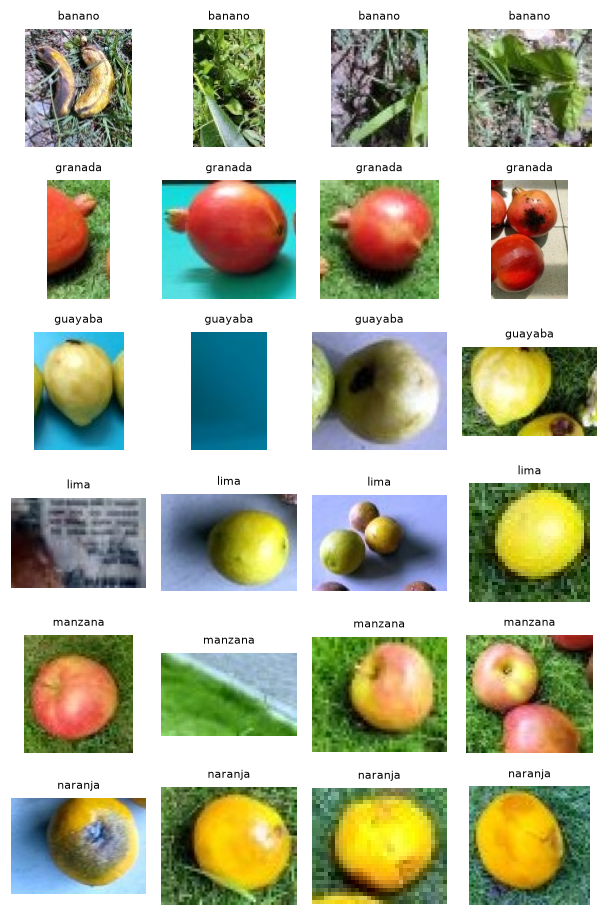

In [10]:
ejemplos = rec.groupby("fruta").sample(4, random_state=SEMILLA, replace=True)
fig, axes = plt.subplots(len(frutas), 4, figsize=(5.6, 1.4 * len(frutas)))
for ax, (_, r) in zip(axes.ravel(), ejemplos.iterrows()):
    ax.imshow(leer_rgb(DATA_INTERIM / "mixed" / "imagenes" / r["recorte"]))
    ax.set_title(r["fruta"], fontsize=7); ax.axis("off")
fig.tight_layout()
guardar_figura(fig, "mixed_recortes", raster=True)
plt.show()

## 5. Conclusiones de la preparación

- El umbral de Otsu calculado a mano coincide con el de OpenCV, lo que verifica la implementación de $\sigma_B^2(t)$.
- Otsu sobre la distancia al fondo funciona con fondos uniformes (el caso de las fotos propias), pero falla con pasto, telas o manos. GrabCut, inicializado con la intersección de Otsu sobre $\Delta E$ y sobre la saturación, corrige la mayoría de esos casos. Sigue fallando cuando el fondo es tan saturado como la fruta (pasto) o cuando la fruta ocupa toda la imagen.
- Entre el 1 % y el 15 % de las máscaras de la muestra se marcan como dudosas (tocan el borde o tienen un área extrema). En la fase de modelado esas imágenes se revisan o se excluyen del cálculo de características de forma.
- En el dataset el diámetro normalizado mide el tamaño **relativo** dentro de la foto: no hay escala física y muchas fotos tienen varias frutas. Los umbrales P33/P66 por fruta quedan en `experiments/results/umbrales_tamano.json`. La validación del tamaño físico se hará con las fotos propias, tomadas a 30 cm con el diámetro medido en cm.
- En `mixed_quality` se obtuvieron 5.301 recortes de 1.073 imágenes con watershed sobre la transformada de distancia, con filtros de tamaño mínimo y compacidad para descartar franjas del fondo. Persisten errores con fondos muy cargados (papel periódico) y frutas de menos de unos 20 px. Por eso el índice `recortes_mixed.csv` tiene las columnas `valido` y `calidad` para revisión manual.